<a href="https://colab.research.google.com/github/tegga8/GEN_AI_Fundamentals/blob/main/RNNs_and_LSTMs_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, Dense, Dropout, Input
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)

VOCAB_SIZE = 10000
MAX_LENGTH = 200
EMBEDDING_DIM = 64
BATCH_SIZE = 128
EPOCHS = 5

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=VOCAB_SIZE
)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))
print("First review token IDs:", x_train[0][:20])
print("First review label:", y_train[0])

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 25000
Testing samples: 25000
First review token IDs: [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]
First review label: 1


In [2]:
x_train = pad_sequences(
    x_train,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

x_test = pad_sequences(
    x_test,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

print("Training shape:", x_train.shape)
print("Testing shape:", x_test.shape)

Training shape: (25000, 200)
Testing shape: (25000, 200)


In [3]:
def build_rnn_model():
    model = Sequential([
        Input(shape=(MAX_LENGTH,)),
        Embedding(VOCAB_SIZE, EMBEDDING_DIM, mask_zero=True),
        SimpleRNN(64),
        Dropout(0.3),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


rnn_model = build_rnn_model()
rnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 648,321 (2.47 MB)

 Trainable params: 648,321 (2.47 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
rnn_history = rnn_model.fit(
    x_train,
    y_train,
    validation_split=0.2,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 24s 132ms/step - accuracy: 0.5781 - loss: 0.6801 - val_accuracy: 0.6964 - val_loss: 0.6402
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 41s 134ms/step - accuracy: 0.7971 - loss: 0.4706 - val_accuracy: 0.7990 - val_loss: 0.4528
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 40s 129ms/step - accuracy: 0.8541 - loss: 0.3489 - val_accuracy: 0.8002 - val_loss: 0.5079
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 19s 120ms/step - accuracy: 0.9268 - loss: 0.1986 - val_accuracy: 0.8116 - val_loss: 0.5657
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 22s 128ms/step - accuracy: 0.9552 - loss: 0.1287 - val_accuracy: 0.7856 - val_loss: 0.6205


In [5]:
def build_lstm_model():
    model = Sequential([
        Input(shape=(MAX_LENGTH,)),
        Embedding(VOCAB_SIZE, EMBEDDING_DIM, mask_zero=True),
        LSTM(64),
        Dropout(0.3),
        Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


lstm_model = build_lstm_model()
lstm_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
lstm_history = lstm_model.fit(
    x_train,
    y_train,
    validation_split=0.2,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=1
)

Epoch 1/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 58s 353ms/step - accuracy: 0.7258 - loss: 0.5170 - val_accuracy: 0.8436 - val_loss: 0.4091
Epoch 2/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 82s 353ms/step - accuracy: 0.8813 - loss: 0.3045 - val_accuracy: 0.8598 - val_loss: 0.3347
Epoch 3/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 58s 367ms/step - accuracy: 0.9140 - loss: 0.2385 - val_accuracy: 0.8452 - val_loss: 0.3685
Epoch 4/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 58s 366ms/step - accuracy: 0.9277 - loss: 0.2017 - val_accuracy: 0.8592 - val_loss: 0.3648
Epoch 5/5
157/157 ━━━━━━━━━━━━━━━━━━━━ 57s 366ms/step - accuracy: 0.9258 - loss: 0.1995 - val_accuracy: 0.8344 - val_loss: 0.4561


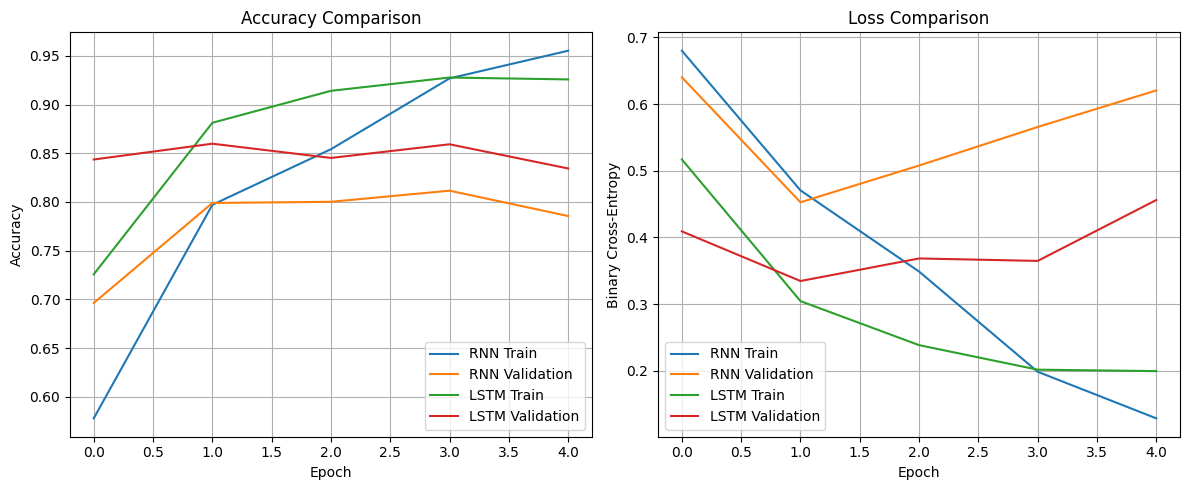

In [7]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(rnn_history.history["accuracy"], label="RNN Train")
plt.plot(rnn_history.history["val_accuracy"], label="RNN Validation")
plt.plot(lstm_history.history["accuracy"], label="LSTM Train")
plt.plot(lstm_history.history["val_accuracy"], label="LSTM Validation")
plt.title("Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(rnn_history.history["loss"], label="RNN Train")
plt.plot(rnn_history.history["val_loss"], label="RNN Validation")
plt.plot(lstm_history.history["loss"], label="LSTM Train")
plt.plot(lstm_history.history["val_loss"], label="LSTM Validation")
plt.title("Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [8]:
rnn_loss, rnn_accuracy = rnn_model.evaluate(
    x_test, y_test, verbose=0
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(
    x_test, y_test, verbose=0
)

print(f"RNN  - Test Loss: {rnn_loss:.4f}, Test Accuracy: {rnn_accuracy:.4f}")
print(f"LSTM - Test Loss: {lstm_loss:.4f}, Test Accuracy: {lstm_accuracy:.4f}")

print("\nRNN Classification Report")
rnn_predictions = (rnn_model.predict(x_test, verbose=0).ravel() >= 0.5).astype(int)
print(classification_report(y_test, rnn_predictions, target_names=["Negative", "Positive"]))

print("\nLSTM Classification Report")
lstm_predictions = (lstm_model.predict(x_test, verbose=0).ravel() >= 0.5).astype(int)
print(classification_report(y_test, lstm_predictions, target_names=["Negative", "Positive"]))

RNN  - Test Loss: 0.6475, Test Accuracy: 0.7822
LSTM - Test Loss: 0.5326, Test Accuracy: 0.8130

RNN Classification Report
              precision    recall  f1-score   support

    Negative       0.83      0.71      0.77     12500
    Positive       0.75      0.85      0.80     12500

    accuracy                           0.78     25000
   macro avg       0.79      0.78      0.78     25000
weighted avg       0.79      0.78      0.78     25000


LSTM Classification Report
              precision    recall  f1-score   support

    Negative       0.75      0.93      0.83     12500
    Positive       0.91      0.70      0.79     12500

    accuracy                           0.81     25000
   macro avg       0.83      0.81      0.81     25000
weighted avg       0.83      0.81      0.81     25000



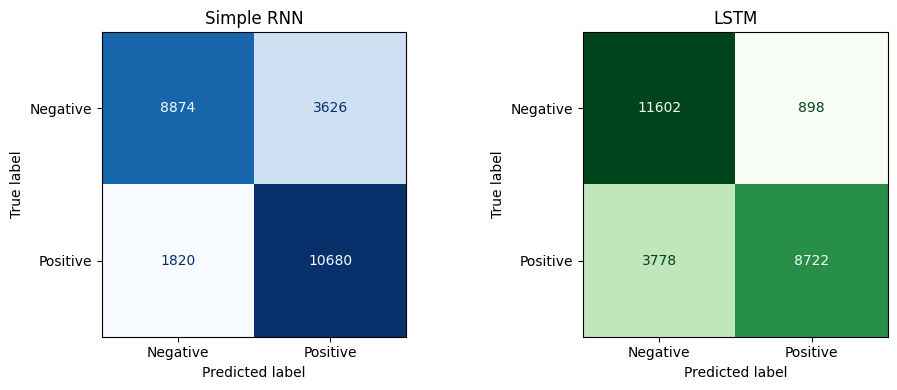

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay(
    confusion_matrix(y_test, rnn_predictions),
    display_labels=["Negative", "Positive"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)

axes[0].set_title("Simple RNN")

ConfusionMatrixDisplay(
    confusion_matrix(y_test, lstm_predictions),
    display_labels=["Negative", "Positive"]
).plot(ax=axes[1], cmap="Greens", colorbar=False)

axes[1].set_title("LSTM")

plt.tight_layout()
plt.show()

In [10]:
results = {
    "Model": ["Simple RNN", "LSTM"],
    "Test Loss": [rnn_loss, lstm_loss],
    "Test Accuracy": [rnn_accuracy, lstm_accuracy]
}

import pandas as pd

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

     Model  Test Loss  Test Accuracy
Simple RNN   0.647529        0.78216
      LSTM   0.532636        0.81296


In [11]:
word_index = imdb.get_word_index()

# IMDB reserves IDs 0-3 for padding and special tokens.
word_index = {
    word: index + 3
    for word, index in word_index.items()
}

word_index["<PAD>"] = 0
word_index["<START>"] = 1
word_index["<UNK>"] = 2
word_index["<UNUSED>"] = 3


def encode_review(text):
    tokens = text.lower().split()

    sequence = [1]

    for token in tokens:
        # Basic word lookup; unknown words map to <UNK>.
        sequence.append(word_index.get(token, 2))

    sequence = [
        token if token < VOCAB_SIZE else 2
        for token in sequence
    ]

    return pad_sequences(
        [sequence],
        maxlen=MAX_LENGTH,
        padding="post",
        truncating="post"
    )


def predict_sentiment(model, review):
    encoded = encode_review(review)
    probability = float(model.predict(encoded, verbose=0)[0][0])

    sentiment = "Positive" if probability >= 0.5 else "Negative"

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print(f"Positive probability: {probability:.4f}")


predict_sentiment(
    lstm_model,
    "This movie was amazing, the acting was brilliant and the story was beautiful"
)

predict_sentiment(
    lstm_model,
    "The movie was boring, poorly written and a complete waste of time, but was a hell lot of fun"
)

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Review: This movie was amazing, the acting was brilliant and the story was beautiful
Predicted sentiment: Positive
Positive probability: 0.6474
Review: The movie was boring, poorly written and a complete waste of time
Predicted sentiment: Negative
Positive probability: 0.0081


Review: The movie was boring, poorly written and a complete waste of time, but was a hell lot of fun amazing and honestly everyone on the planet should see this, it is very good amazing and trash at the same time but not anymore it is good very very very good 
Predicted sentiment: Positive
Positive probability: 0.7860


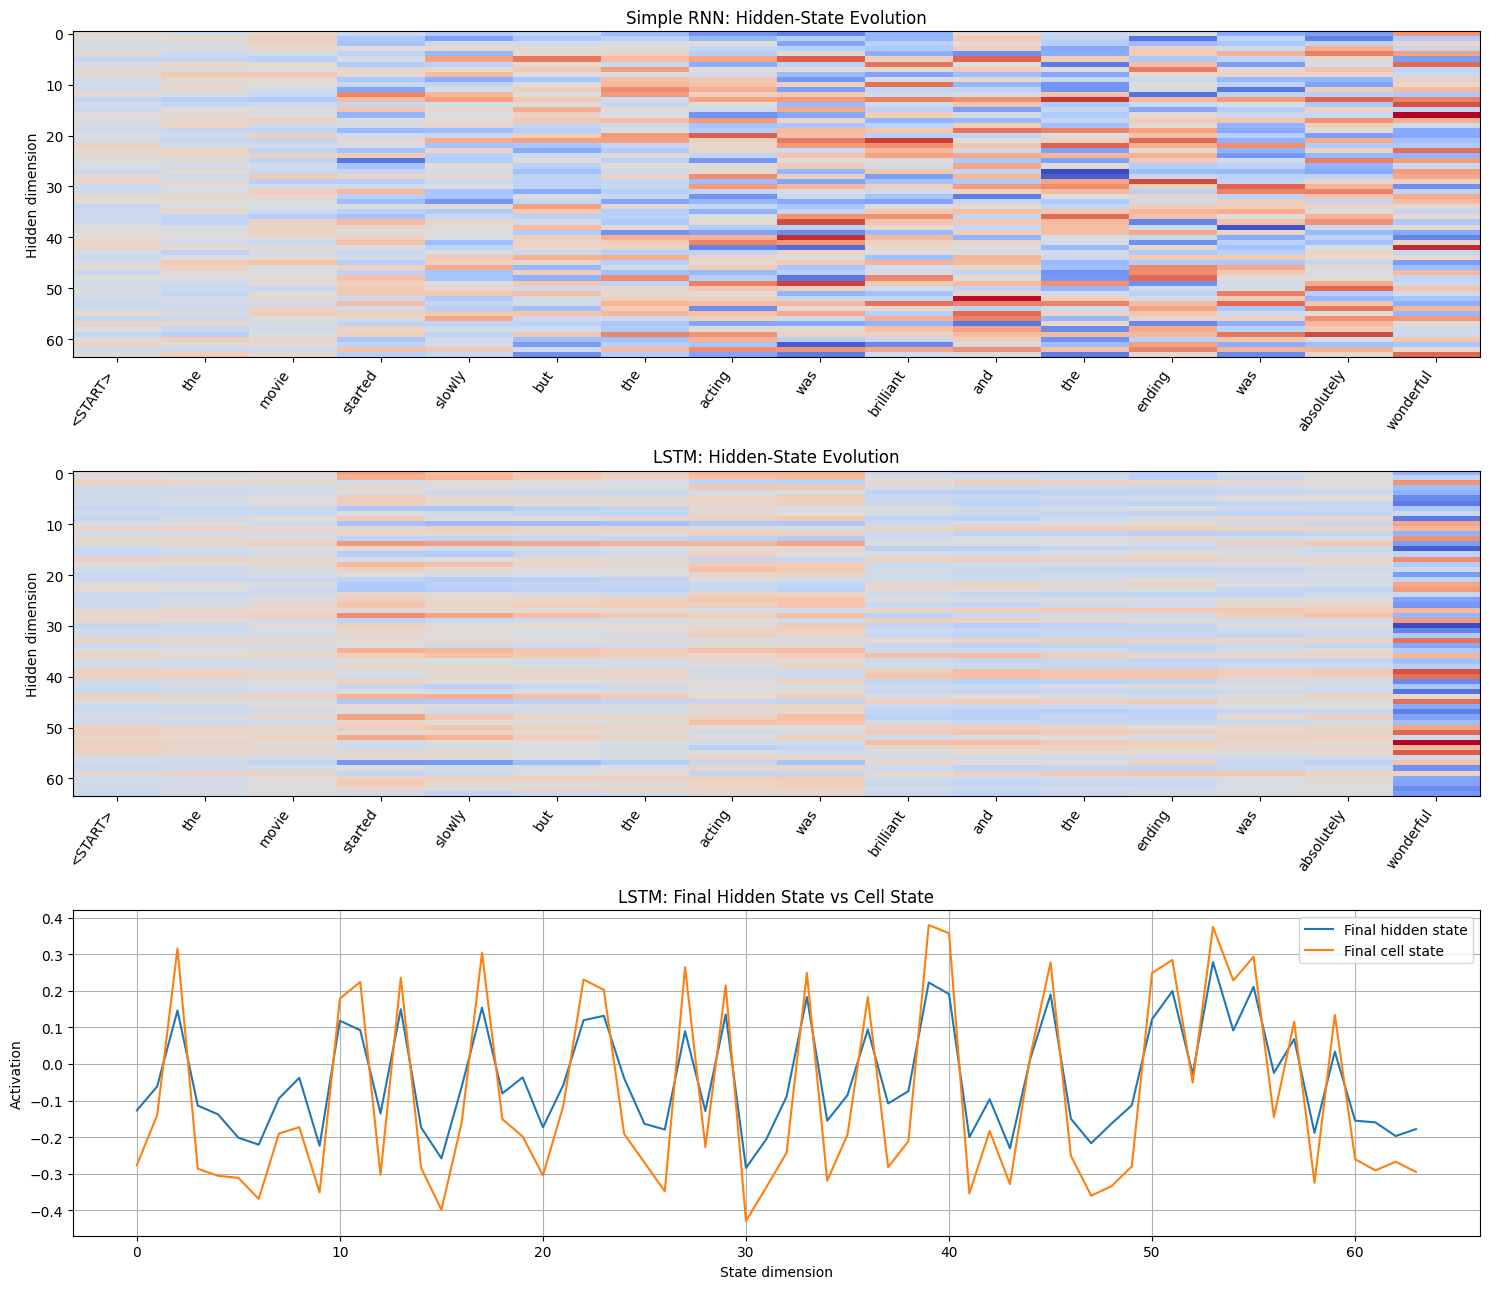

In [20]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, SimpleRNN, LSTM

# Sample review
review = "The movie started slowly but the acting was brilliant and the ending was absolutely wonderful"
encoded = encode_review(review)

# Reuse trained embedding layers
rnn_embedding = rnn_model.layers[0]
trained_rnn = rnn_model.layers[1]

lstm_embedding = lstm_model.layers[0]
trained_lstm = lstm_model.layers[1]

# Build RNN hidden-state model
rnn_in = Input(shape=(MAX_LENGTH,), dtype="int32")
rnn_emb = rnn_embedding(rnn_in)
rnn_layer = SimpleRNN(64, return_sequences=True)
rnn_out = rnn_layer(rnn_emb)
rnn_inspector = Model(rnn_in, rnn_out)
rnn_layer.set_weights(trained_rnn.get_weights())

# Build LSTM hidden-state and cell-state model
lstm_in = Input(shape=(MAX_LENGTH,), dtype="int32")
lstm_emb = lstm_embedding(lstm_in)
lstm_layer = LSTM(64, return_sequences=True, return_state=True)
lstm_seq, final_h, final_c = lstm_layer(lstm_emb)
lstm_inspector = Model(lstm_in, [lstm_seq, final_h, final_c])
lstm_layer.set_weights(trained_lstm.get_weights())

# Extract states
rnn_states = rnn_inspector.predict(encoded, verbose=0)[0]
lstm_states, h_T, c_T = lstm_inspector.predict(encoded, verbose=0)

# Recover tokens
reverse_word_index = {v: k for k, v in word_index.items()}
positions = np.where(encoded[0] != 0)[0][:30]
words = [
    reverse_word_index.get(int(encoded[0, i]), "<UNK>")
    for i in positions
]

# Plot all three visualizations
fig, axes = plt.subplots(3, 1, figsize=(15, 13))

axes[0].imshow(rnn_states[positions].T, aspect="auto", cmap="coolwarm")
axes[0].set_title("Simple RNN: Hidden-State Evolution")
axes[0].set_ylabel("Hidden dimension")
axes[0].set_xticks(range(len(words)))
axes[0].set_xticklabels(words, rotation=55, ha="right")

axes[1].imshow(lstm_states[0, positions].T, aspect="auto", cmap="coolwarm")
axes[1].set_title("LSTM: Hidden-State Evolution")
axes[1].set_ylabel("Hidden dimension")
axes[1].set_xticks(range(len(words)))
axes[1].set_xticklabels(words, rotation=55, ha="right")

axes[2].plot(h_T[0], label="Final hidden state")
axes[2].plot(c_T[0], label="Final cell state")
axes[2].set_title("LSTM: Final Hidden State vs Cell State")
axes[2].set_xlabel("State dimension")
axes[2].set_ylabel("Activation")
axes[2].legend()
axes[2].grid(True)

plt.tight_layout()
plt.show()
